# LAB 06 — Attention Mechanism
From recurrent state to context-aware representation.

- **Core implementation** (`attention_numpy.py`): scaled dot-product attention, softmax ổn định số và self-attention bằng NumPy, không dùng `torch.nn.MultiheadAttention` / `keras.layers.Attention`.
- **Dữ liệu:** IMDb, chia 60/20/20 stratified seed 2026 giống LAB 04–05 (train 29,746 / val 9,916 / test 9,916), vocabulary 20,000 từ chỉ từ train, max_length 200.
- Các model trong Experiment 4 được huấn luyện trên **Kaggle (GPU)**; kết quả lưu trong `cache/`, chạy lại notebook ở local sẽ nạp cache (xóa `cache/` để train lại).

In [1]:
import sys, os, time, csv, random, warnings
from collections import Counter
sys.path.insert(0, "../lab04")                       # dùng lại preprocessing của LAB 04 (cùng split)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import preprocessing as pp
import attention_numpy as an
from attention_numpy import softmax, entropy, scaled_dot_product_attention, self_attention
warnings.filterwarnings("ignore")
SEED = 2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
np.set_printoptions(precision=4, suppress=True)
RESULTS = []
def log(exp, cfg, metric, val): RESULTS.append((exp, cfg, metric, val))
os.makedirs("cache", exist_ok=True)

## 16–17. Core implementation và numerical stability
`scaled_dot_product_attention(Q, K, V)` trả về `scores`, `attention_weights`, `context`:
S = QKᵀ / √d_k → A = softmax(S) → C = AV. Softmax trừ max trước khi exp. Hàm có thêm `mask` (bỏ PAD), `scale=False` (dot-product thường) và `temperature`.

In [2]:
an._tests()                                           # khớp các bài tính tay và khớp torch.nn.functional.scaled_dot_product_attention
print("Bài 1  scores s = Kq =", np.array([[1,0],[0,1],[1,1]]) @ np.array([1,2]))
a = softmax([1,2,3]); print("Bài 2  softmax([1,2,3]) =", a, "| tổng =", a.sum())
print("Bài 3  c =", np.array([0.1,0.2,0.7]) @ np.array([[1,0],[0,1],[2,2]]))
s, w, c = scaled_dot_product_attention([[1,0]], [[1,0],[0,1],[1,1]], [[1,0],[0,2],[2,1]], scale=False)
print("Bài 4  scores =", s[0], "| weights =", w[0], "| context =", c[0])
print("Mục 14 không scaling:", softmax([4,2,0]), "| chia √4:", softmax(np.array([4,2,0])/2))
x = np.array([1000., 1001., 1002.])
with np.errstate(over="ignore", invalid="ignore"): print("Mục 17 np.exp trực tiếp:", an.softmax_naive(x), "| trừ max:", softmax(x))
for k, v in (("bai1_scores", "1,2,3"), ("bai4_context", ",".join(f"{t:.4f}" for t in c[0]))): log("calc", "numpy", k, v)

khớp torch.nn.functional.scaled_dot_product_attention: OK
all tests passed
Bài 1  scores s = Kq = [1 2 3]
Bài 2  softmax([1,2,3]) = [0.09   0.2447 0.6652] | tổng = 0.9999999999999999
Bài 3  c = [1.5 1.6]
Bài 4  scores = [1. 0. 1.] | weights = [0.4223 0.1554 0.4223] | context = [1.267 0.733]
Mục 14 không scaling: [0.8668 0.1173 0.0159] | chia √4: [0.6652 0.2447 0.09  ]
Mục 17 np.exp trực tiếp: [nan nan nan] | trừ max: [0.09   0.2447 0.6652]


## 21–22. Self-attention (bài tập 21) và attention matrix
X (I, like, cats) và W_Q, W_K, W_V tự chọn như trong `calculations.md`. Mỗi hàng của attention matrix A cho biết token đó attend tới token nào; mỗi hàng tổng bằng 1.

Q =
 [[1. 0.]
 [1. 1.]
 [2. 1.]] 
K =
 [[1. 1.]
 [0. 1.]
 [1. 2.]] 
V =
 [[1. 0.]
 [0. 2.]
 [1. 2.]] 
QKᵀ =
 [[1. 0. 1.]
 [2. 1. 3.]
 [3. 1. 4.]]


,I,like,cats
query \ key,,,
I,0.401,0.198,0.401
like,0.284,0.140,0.576
cats,0.306,0.074,0.620


,out1,out2
I,0.802,1.198
like,0.860,1.432
cats,0.926,1.389


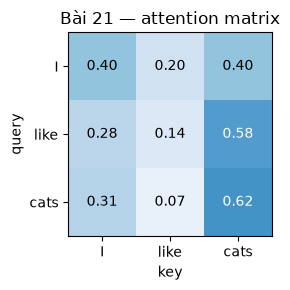

In [3]:
Q, K, V, S, A, O = self_attention(an.BAI21_X, an.BAI21_WQ, an.BAI21_WK, an.BAI21_WV)
toks21 = ["I", "like", "cats"]
print("Q =\n", Q, "\nK =\n", K, "\nV =\n", V, "\nQKᵀ =\n", Q @ K.T)
display(pd.DataFrame(A, index=toks21, columns=toks21).round(3).rename_axis("query \\ key"))
display(pd.DataFrame(O, index=toks21, columns=["out1", "out2"]).round(3))
fig, ax = plt.subplots(figsize=(3.4, 3)); im = ax.imshow(A, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(toks21); ax.set_yticks(range(3)); ax.set_yticklabels(toks21); ax.set_xlabel("key"); ax.set_ylabel("query")
for i in range(3):
    for j in range(3): ax.text(j, i, f"{A[i,j]:.2f}", ha="center", va="center", color="white" if A[i,j] > .5 else "black")
ax.set_title("Bài 21 — attention matrix"); plt.tight_layout(); plt.show()
log("calc", "bai21", "A_row_like", ",".join(f"{t:.3f}" for t in A[1]))

## 12. Kiểm tra Prediction 2 và 3 (trước khi làm experiment)

In [4]:
for s in ([1,1,1,1], [1,1,10]):
    p = softmax(s); print(f"softmax({s}) = {p} | max weight = {p.max():.4f} | entropy = {entropy(p):.4f}")
    log("prediction_check", str(s).replace(",", ";"), "weights", ";".join(f"{t:.4f}" for t in p))

softmax([1, 1, 1, 1]) = [0.25 0.25 0.25 0.25] | max weight = 0.2500 | entropy = 1.3863
softmax([1, 1, 10]) = [0.0001 0.0001 0.9998] | max weight = 0.9998 | entropy = 0.0025


## Dữ liệu, tokenizer và vocabulary
Giống LAB 05: split 60/20/20 seed 2026, vocabulary 20,000 từ (chỉ từ train, PAD = 0, UNK = 1), giữ 200 token đầu và pad bên phải.

In [5]:
data = pp.prepare(pp.load_imdb())
train, val, test = (d.reset_index(drop=True) for d in pp.split(data))
print("train/val/test:", len(train), len(val), len(test))
cnt = Counter(w for t in train.text for w in pp.tokenize(t))
itos = ["<pad>", "<unk>"] + [w for w, c in cnt.most_common() if c >= 3][:19998]
stoi = {w: i for i, w in enumerate(itos)}; MAXLEN = 200
print("vocabulary size:", len(itos))
def encode(texts, L=MAXLEN):
    rows, lens = [], []
    for t in texts:
        ids = [stoi.get(w, 1) for w in pp.tokenize(t)][:L] or [1]
        lens.append(len(ids)); rows.append(ids + [0]*(L-len(ids)))
    return torch.tensor(rows), torch.tensor(lens)

train/val/test: 29746 9916 9916


vocabulary size: 20000


## Word2Vec cho query giả lập (Experiment 1–3)
Experiment 1–3 không cần huấn luyện classifier: key/value là vector Word2Vec (100 chiều, train trên tập train IMDb) của từng token, query do mình đặt. Mọi vector được chuẩn hóa về độ dài √d (d = 100), nên scaled score qᵀk / √d = √d · cos(q, k) = 10 · cos(q, k).

In [6]:
from gensim.models import Word2Vec
W2V_PATH = "cache/w2v_train.model"
if os.path.exists(W2V_PATH): w2v = Word2Vec.load(W2V_PATH)
else:
    w2v = Word2Vec([pp.tokenize(t) for t in train.text], vector_size=100, window=5, min_count=3, workers=4, seed=SEED, epochs=5)
    w2v.save(W2V_PATH)
D = w2v.vector_size
def unit(v): v = np.asarray(v, float); return v / np.linalg.norm(v) * np.sqrt(D)      # độ dài √d
def vecs(tokens): return np.stack([unit(w2v.wv[t]) for t in tokens])
def query(words): return unit(np.mean([w2v.wv[w] / np.linalg.norm(w2v.wv[w]) for w in words], axis=0))
print("most_similar('good'):", [w for w, _ in w2v.wv.most_similar("good", topn=6)])

most_similar('good'): ['decent', 'bad', 'great', 'nice', 'cool', 'fine']


## 18. Experiment 1 — Attention distribution
Câu *"The movie was surprisingly good despite a very slow beginning."*; K = V = vector Word2Vec của từng token; **query sentiment** = trung bình vector của các từ đánh giá (good, bad, great, terrible, boring, excellent).

,Score,Attention
Token,,
the,3.764,0.007
movie,4.034,0.009
was,0.632,0.000
surprisingly,2.261,0.002
good,8.658,0.964
despite,0.446,0.000
a,1.576,0.001
very,2.561,0.002
slow,4.196,0.011


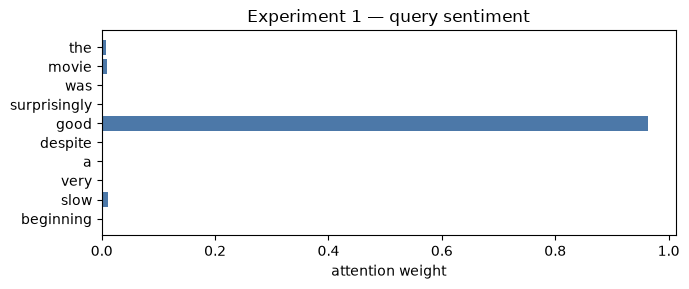

max weight = 0.964 | entropy = 0.216 (phân phối đều: 2.303)


In [7]:
sent = "The movie was surprisingly good despite a very slow beginning."
toks = pp.tokenize(sent); Kx = vecs(toks)
SENT_WORDS = ["good", "bad", "great", "terrible", "boring", "excellent"]
TOPIC_WORDS = ["movie", "film", "plot", "scene", "story", "actor"]
qA = query(SENT_WORDS)
sc, wA, ctx = scaled_dot_product_attention(qA[None], Kx, Kx)
t1 = pd.DataFrame({"Token": toks, "Score": sc[0].round(3), "Attention": wA[0].round(3)})
display(t1.set_index("Token"))
fig, ax = plt.subplots(figsize=(7, 3)); ax.barh(toks[::-1], wA[0][::-1], color="#4c78a8"); ax.set_xlabel("attention weight")
ax.set_title("Experiment 1 — query sentiment"); plt.tight_layout(); plt.show()
print("max weight = %.3f | entropy = %.3f (phân phối đều: %.3f)" % (wA.max(), entropy(wA[0]), np.log(len(toks))))
for t, s_, a_ in zip(toks, sc[0], wA[0]): log("exp1_distribution", t, "attention", round(float(a_), 4))

**Nhận xét Experiment 1:** query sentiment dồn gần hết weight vào **good** (0.964); kế tiếp là slow (0.011) và movie (0.009); các từ chức năng (was, despite, a) gần 0. Phân phối rất tập trung (entropy 0.22 so với 2.30 khi đều) vì score = 10·cos nên chênh lệch score lớn (8.66 so với ≤ 4.2). "surprisingly" và "slow" cũng mang sắc thái đánh giá nhưng cosine với query thấp hơn nhiều, nên gần như bị bỏ qua: attention chọn theo **độ tương đồng vector với query**, không theo ý nghĩa cả câu.

## 19. Experiment 2 — Query thay đổi (sentiment vs topic)
Cùng câu, cùng K/V; **query topic** = trung bình vector của movie, film, plot, scene, story, actor.

,Query A (sentiment),Query B (topic)
Token,,
the,0.007,0.001
movie,0.009,0.961
was,0.000,0.001
surprisingly,0.002,0.005
good,0.964,0.004
despite,0.000,0.000
a,0.001,0.001
very,0.002,0.006
slow,0.011,0.015


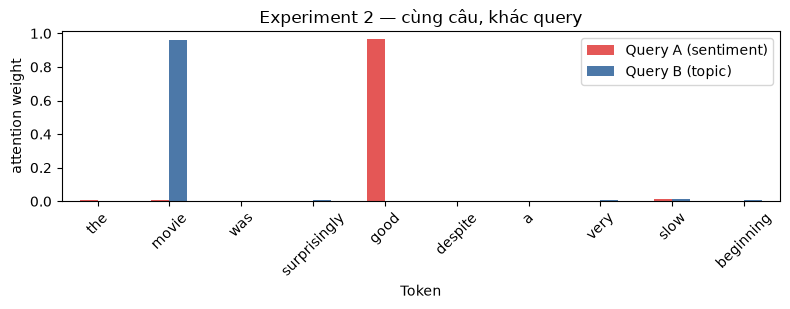

top-3 query A: ['good', 'slow', 'movie'] | top-3 query B: ['movie', 'slow', 'beginning']


In [8]:
qB = query(TOPIC_WORDS)
_, wB, _ = scaled_dot_product_attention(qB[None], Kx, Kx)
t2 = pd.DataFrame({"Token": toks, "Query A (sentiment)": wA[0].round(3), "Query B (topic)": wB[0].round(3)}).set_index("Token")
display(t2)
ax = t2.plot.bar(rot=45, figsize=(8, 3.2), color=["#e45756", "#4c78a8"]); ax.set_ylabel("attention weight"); ax.set_title("Experiment 2 — cùng câu, khác query"); plt.tight_layout(); plt.show()
print("top-3 query A:", list(t2.iloc[:,0].sort_values(ascending=False).index[:3]), "| top-3 query B:", list(t2.iloc[:,1].sort_values(ascending=False).index[:3]))
for t in toks: log("exp2_query", t, "sentiment|topic", f"{t2.loc[t].iloc[0]:.3f}|{t2.loc[t].iloc[1]:.3f}")

**Nhận xét Experiment 2:** cùng câu, cùng key/value, chỉ đổi query thì phân phối đổi hẳn: query sentiment chọn **good** (0.964), query topic chọn **movie** (0.961). Attention không phải danh sách "từ quan trọng nhất" cố định của câu; nó phụ thuộc vào **query** (đang cần thông tin gì).

## 14–15. Scaling và temperature
(a) Temperature trên score vector [2, 1, 0] (giống bài tính tay) và trên score thật của Experiment 1. (b) Vì sao chia √d_k: với q, k ngẫu nhiên chuẩn, độ lệch chuẩn của qᵀk tăng theo √d nên softmax không scale bão hòa khi d lớn.

Max_weight  Entropy
scores         Temperature                     
[2,1,0]        0.5               0.867    0.441
               1.0               0.665    0.832
               2.0               0.506    1.020
Exp1 sentiment 0.5               1.000    0.003
               1.0               0.964    0.216
               2.0               0.667    1.311

,score_std,max_weight_unscaled,max_weight_scaled,entropy_unscaled,entropy_scaled
d_k,,,,,
4,2.03,0.494,0.305,1.431,1.946
16,3.97,0.727,0.317,0.741,1.931
64,7.95,0.861,0.312,0.359,1.938
256,15.98,0.932,0.318,0.168,1.926
1024,31.97,0.969,0.319,0.076,1.926


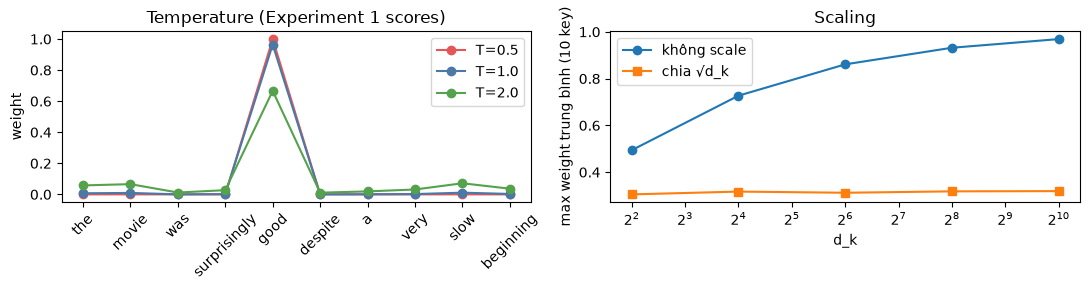

In [9]:
rows = []
for name, s in (("[2,1,0]", np.array([2., 1., 0.])), ("Exp1 sentiment", sc[0])):
    for T in (0.5, 1.0, 2.0):
        p = softmax(s / T); rows.append(dict(scores=name, Temperature=T, Max_weight=round(p.max(), 3), Entropy=round(float(entropy(p)), 3)))
        log("exp_temperature", f"{name}|T={T}", "max_weight|entropy", f"{p.max():.4f}|{entropy(p):.4f}")
tT = pd.DataFrame(rows); display(tT.set_index(["scores", "Temperature"]))
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for T, c in ((0.5, "#e45756"), (1.0, "#4c78a8"), (2.0, "#54a24b")): ax[0].plot(toks, softmax(sc[0] / T), "o-", color=c, label=f"T={T}")
ax[0].set_title("Temperature (Experiment 1 scores)"); ax[0].tick_params(axis="x", rotation=45); ax[0].legend(); ax[0].set_ylabel("weight")
rng = np.random.default_rng(SEED); rows = []
for d in (4, 16, 64, 256, 1024):
    q_, k_ = rng.normal(size=(2000, 1, d)), rng.normal(size=(2000, 10, d))       # 2000 lần, mỗi lần 10 key
    s_ = (q_ @ np.swapaxes(k_, 1, 2))[:, 0]
    pu, ps = softmax(s_), softmax(s_ / np.sqrt(d))
    rows.append(dict(d_k=d, score_std=round(s_.std(), 2), max_weight_unscaled=round(pu.max(1).mean(), 3), max_weight_scaled=round(ps.max(1).mean(), 3),
                     entropy_unscaled=round(entropy(pu).mean(), 3), entropy_scaled=round(entropy(ps).mean(), 3)))
    log("exp_scaling", f"d_k={d}", "max_weight_unscaled|scaled", f"{rows[-1]['max_weight_unscaled']}|{rows[-1]['max_weight_scaled']}")
tS = pd.DataFrame(rows).set_index("d_k"); display(tS)
ax[1].plot(tS.index, tS.max_weight_unscaled, "o-", label="không scale"); ax[1].plot(tS.index, tS.max_weight_scaled, "s-", label="chia √d_k")
ax[1].set_xscale("log", base=2); ax[1].set_xlabel("d_k"); ax[1].set_ylabel("max weight trung bình (10 key)"); ax[1].set_title("Scaling"); ax[1].legend()
plt.tight_layout(); plt.show()

**Nhận xét scaling / temperature:**
- Temperature: T = 0.5 → 1 → 2 làm max weight giảm 0.867 → 0.665 → 0.506 và entropy tăng 0.44 → 0.83 → 1.02 (score [2, 1, 0]); với score thật của Experiment 1, T = 0.5 gần one-hot (1.000) còn T = 2 phẳng hơn rõ (0.667). Thứ tự các weight không đổi.
- Scaling: với vector ngẫu nhiên, độ lệch chuẩn của qᵀk ≈ √d_k (2.0 → 32.0 khi d_k = 4 → 1024). Không chia √d_k thì max weight tăng 0.49 → 0.97 (softmax gần one-hot, gradient gần 0); chia √d_k thì max weight giữ ổn định ≈ 0.31 và entropy ≈ 1.93 ở mọi d_k. Chia √d_k tương đương temperature T = √d_k, giữ score ở cùng thang đo bất kể số chiều.

## Mô hình (Experiment 4) — LSTM vs Self-attention classifier
- **LSTM** (giống LAB 05): embedding 100 → LSTM 128 → hidden state cuối → linear.
- **ATT**: embedding 100 + positional embedding (học được) → **self-attention một head tự viết** (Q, K, V = XW, scores QKᵀ/√d, mask PAD, softmax, AV) + residual + LayerNorm → **attention pooling** (một query học được tính weight cho từng vị trí → context vector) → linear.
- Ablation: **ATT_nopos** (bỏ positional embedding: self-attention không biết thứ tự) và **POOL** (chỉ attention pooling trên embedding, không có self-attention).

Cùng điều kiện: Adam lr 2e-3, batch 64, 8 epoch, dropout 0.3, gradient clipping 1.0, chọn epoch có validation loss thấp nhất.

In [10]:
EPOCHS, BATCH, LR = 8, 64, 2e-3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu"); print("device:", DEVICE)
class LSTMClassifier(nn.Module):
    def __init__(self, vocab, emb=100, hid=128, drop=0.3):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb, padding_idx=0); self.rnn = nn.LSTM(emb, hid, batch_first=True)
        self.drop, self.fc = nn.Dropout(drop), nn.Linear(hid, 1)
    def forward(self, x, lens, return_attn=False):
        p = nn.utils.rnn.pack_padded_sequence(self.emb(x), lens.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.rnn(p); return self.fc(self.drop(h[-1])).squeeze(-1)
class AttnClassifier(nn.Module):
    """Self-attention + attention pooling, tự viết bằng phép nhân ma trận (không dùng nn.MultiheadAttention)."""
    def __init__(self, vocab, d=100, maxlen=MAXLEN, drop=0.3, use_pos=True, use_self=True):
        super().__init__()
        self.d, self.use_pos, self.use_self = d, use_pos, use_self
        self.emb = nn.Embedding(vocab, d, padding_idx=0)
        self.pos = nn.Embedding(maxlen, d) if use_pos else None
        if use_self:
            self.Wq, self.Wk, self.Wv = (nn.Linear(d, d, bias=False) for _ in range(3)); self.norm = nn.LayerNorm(d)
        self.u = nn.Parameter(torch.randn(d) / d**0.5)            # query học được của attention pooling
        self.drop, self.fc = nn.Dropout(drop), nn.Linear(d, 1)
    def forward(self, x, lens=None, return_attn=False):
        pad = x == 0                                               # (B, T) True = PAD
        h = self.emb(x)
        if self.use_pos: h = h + self.pos(torch.arange(x.size(1), device=x.device))[None]
        A = None
        if self.use_self:
            Q, K, V = self.Wq(h), self.Wk(h), self.Wv(h)
            S = Q @ K.transpose(1, 2) / self.d**0.5                # (B, T, T)
            S = S.masked_fill(pad[:, None, :], -1e9)               # không attend tới PAD
            A = torch.softmax(S, dim=-1)
            h = self.norm(h + self.drop(A @ V))                    # residual + LayerNorm
        a = (h @ self.u / self.d**0.5).masked_fill(pad, -1e9)
        alpha = torch.softmax(a, dim=-1)                           # (B, T) weight của từng vị trí
        c = (alpha[..., None] * h).sum(1)                          # context vector
        logit = self.fc(self.drop(c)).squeeze(-1)
        return (logit, A, alpha) if return_attn else logit
MODELS = {"LSTM": lambda: LSTMClassifier(len(itos)), "ATT": lambda: AttnClassifier(len(itos)),
          "ATT_nopos": lambda: AttnClassifier(len(itos), use_pos=False), "POOL": lambda: AttnClassifier(len(itos), use_self=False)}
def n_params(m): return sum(p.numel() for p in m.parameters())
lossf = nn.BCEWithLogitsLoss()
@torch.no_grad()
def predict(model, X, lens, bs=256):
    model.eval(); dev = next(model.parameters()).device; out = []
    for i in range(0, len(X), bs): out.append(torch.sigmoid(model(X[i:i+bs].to(dev), lens[i:i+bs])).cpu())
    return torch.cat(out).numpy()
def metrics(y, p, thr=0.5):
    q = (p >= thr).astype(int)
    return dict(accuracy=accuracy_score(y, q), precision=precision_score(y, q), recall=recall_score(y, q), f1=f1_score(y, q))
def train_run(name, epochs=EPOCHS):
    path = f"cache/{name}.pt"
    if os.path.exists(path): return torch.load(path, map_location="cpu", weights_only=False)
    torch.manual_seed(SEED); np.random.seed(SEED)
    Xtr, ltr = encode(train.text); Xva, lva = encode(val.text); Xte, lte = encode(test.text)
    Xtr = Xtr.to(DEVICE); ytr = torch.tensor(train.label.values, dtype=torch.float32, device=DEVICE); yva = val.label.values
    model = MODELS[name]().to(DEVICE); opt = torch.optim.Adam(model.parameters(), lr=LR)
    hist = dict(train_loss=[], val_loss=[], epoch_s=[]); best = (1e9, None, 0); t_total = 0.0
    for ep in range(epochs):
        model.train(); t0 = time.time(); perm = torch.randperm(len(Xtr)); tl = 0.0
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i+BATCH]; idd = idx.to(DEVICE)
            loss = lossf(model(Xtr[idd], ltr[idx]), ytr[idd])
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); tl += loss.item() * len(idx)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        dt = time.time() - t0; t_total += dt
        pv = predict(model, Xva, lva)
        vl = float(lossf(torch.logit(torch.tensor(pv).clamp(1e-6, 1-1e-6)), torch.tensor(yva, dtype=torch.float32)))
        hist["train_loss"].append(tl/len(Xtr)); hist["val_loss"].append(vl); hist["epoch_s"].append(dt)
        if vl < best[0]: best = (vl, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, ep + 1)
        print(f"{name} ep{ep+1}: train {tl/len(Xtr):.4f} val {vl:.4f} val_acc {((pv>=.5)==yva).mean():.3f} {dt:.1f}s")
    model.load_state_dict(best[1]); pt = predict(model, Xte, lte)
    res = dict(name=name, hist=hist, best_epoch=best[2], epochs=epochs, train_time=t_total, params=n_params(model), device=str(DEVICE),
               test_probs=pt, test_metrics=metrics(test.label.values, pt), state=best[1])
    torch.save(res, path); return res

device: cpu


## 24. Experiment 4 — RNN context vs Attention context (test set)

,Accuracy,Precision,Recall,F1,Training_time_s,Parameters,Best_epoch
Model,,,,,,,
LSTM,0.8543,0.8538,0.8563,0.8551,49.6,2117889,4
ATT,0.8514,0.8434,0.8644,0.8537,21.7,2050401,1
ATT_nopos,0.8721,0.8778,0.8658,0.8717,21.6,2030401,2
POOL,0.8783,0.8640,0.8989,0.8811,11.9,2020201,3


thiết bị huấn luyện: cuda


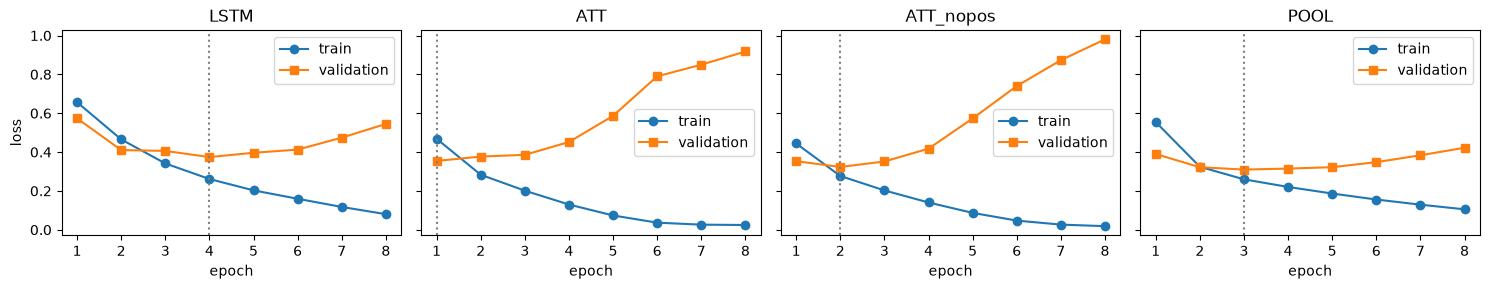

In [11]:
runs = {n: train_run(n) for n in ("LSTM", "ATT", "ATT_nopos", "POOL")}
tab4 = pd.DataFrame([dict(Model=n, Accuracy=round(r["test_metrics"]["accuracy"], 4), Precision=round(r["test_metrics"]["precision"], 4),
                          Recall=round(r["test_metrics"]["recall"], 4), F1=round(r["test_metrics"]["f1"], 4),
                          Training_time_s=round(r["train_time"], 1), Parameters=r["params"], Best_epoch=r["best_epoch"]) for n, r in runs.items()]).set_index("Model")
display(tab4); print("thiết bị huấn luyện:", runs["ATT"]["device"])
for n, r in runs.items():
    for k, v in r["test_metrics"].items(): log("exp4_lstm_vs_attention", n, k, round(v, 4))
    log("exp4_lstm_vs_attention", n, "train_time_s", round(r["train_time"], 1)); log("exp4_lstm_vs_attention", n, "params", r["params"]); log("exp4_lstm_vs_attention", n, "best_epoch", r["best_epoch"])
fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, (n, r) in zip(axes, runs.items()):
    e = range(1, len(r["hist"]["train_loss"]) + 1)
    ax.plot(e, r["hist"]["train_loss"], "o-", label="train"); ax.plot(e, r["hist"]["val_loss"], "s-", label="validation")
    ax.axvline(r["best_epoch"], color="gray", ls=":"); ax.set_title(n); ax.set_xlabel("epoch"); ax.legend()
axes[0].set_ylabel("loss"); plt.tight_layout(); plt.show()

**Nhận xét Experiment 4** (cùng split, cùng GPU Kaggle):
- LSTM (F1 0.855) và ATT (F1 0.854) gần như bằng nhau; ATT train nhanh hơn ≈ 2.3 lần (21.7 s so với 49.6 s cho 8 epoch) vì self-attention tính mọi vị trí **song song**, còn LSTM phải đi tuần tự 200 bước. Số tham số tương đương (≈ 2.05M so với 2.12M; phần lớn là embedding 2M).
- ATT overfit rất nhanh: val loss thấp nhất ở epoch 1 rồi tăng liên tục (0.35 → 0.92) trong khi train loss về 0.02. Bỏ positional embedding (ATT_nopos) lại tốt hơn (F1 0.872), và chỉ dùng attention pooling (POOL) tốt nhất (F1 0.881). Với sentiment trên IMDb, biết **từ nào xuất hiện** quan trọng hơn thứ tự; thêm self-attention + 20,000 tham số vị trí chủ yếu làm model dễ học thuộc hơn trên 30k review.
- **Representation khác nhau ở đâu:** LSTM nén cả câu vào **một hidden state cuối** hₜ, thông tin token đầu phải đi qua ~200 bước cập nhật. Model attention giữ **một vector cho mỗi token**; self-attention cho mỗi token nhìn trực tiếp mọi token khác (1 bước), rồi attention pooling lấy **tổng có trọng số** của tất cả vị trí làm context vector.

## Evaluation — confusion matrix (LSTM vs ATT)

LSTM  TN=4209 FP=730 FN=715 TP=4262
ATT   TN=4140 FP=799 FN=675 TP=4302


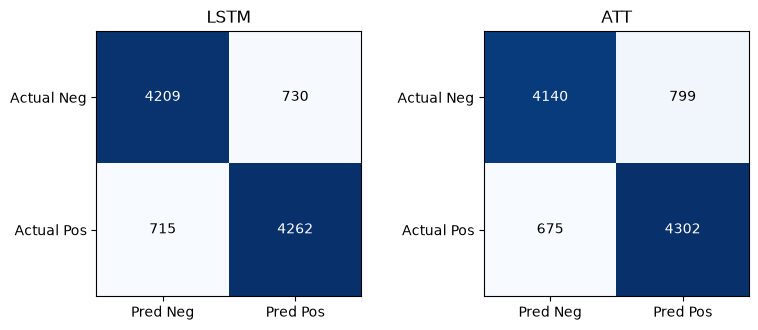

In [12]:
y = test.label.values
fig, axes = plt.subplots(1, 2, figsize=(8, 3.4))
for ax, n in zip(axes, ("LSTM", "ATT")):
    cm = confusion_matrix(y, (runs[n]["test_probs"] >= .5).astype(int)); ax.imshow(cm, cmap="Blues"); ax.set_title(n)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(["Pred Neg", "Pred Pos"]); ax.set_yticklabels(["Actual Neg", "Actual Pos"])
    for i in range(2):
        for j in range(2): ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
    tn, fp, fn, tp = cm.ravel(); log("confusion", n, "TN_FP_FN_TP", f"{tn},{fp},{fn},{tp}"); print(f"{n:5s} TN={tn} FP={fp} FN={fn} TP={tp}")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=130); plt.show()
def load(n):
    m = MODELS[n](); m.load_state_dict(runs[n]["state"]); return m.eval()
att = load("ATT")

## 23. Experiment 3 — Attention visualization
Hai câu có quan hệ ngữ nghĩa rõ. Hàng trên: self-attention **không huấn luyện** trên vector Word2Vec (Q = K = V = X, chỉ đo độ tương đồng). Hàng dưới: attention matrix của layer self-attention trong model **ATT** đã huấn luyện cho sentiment.

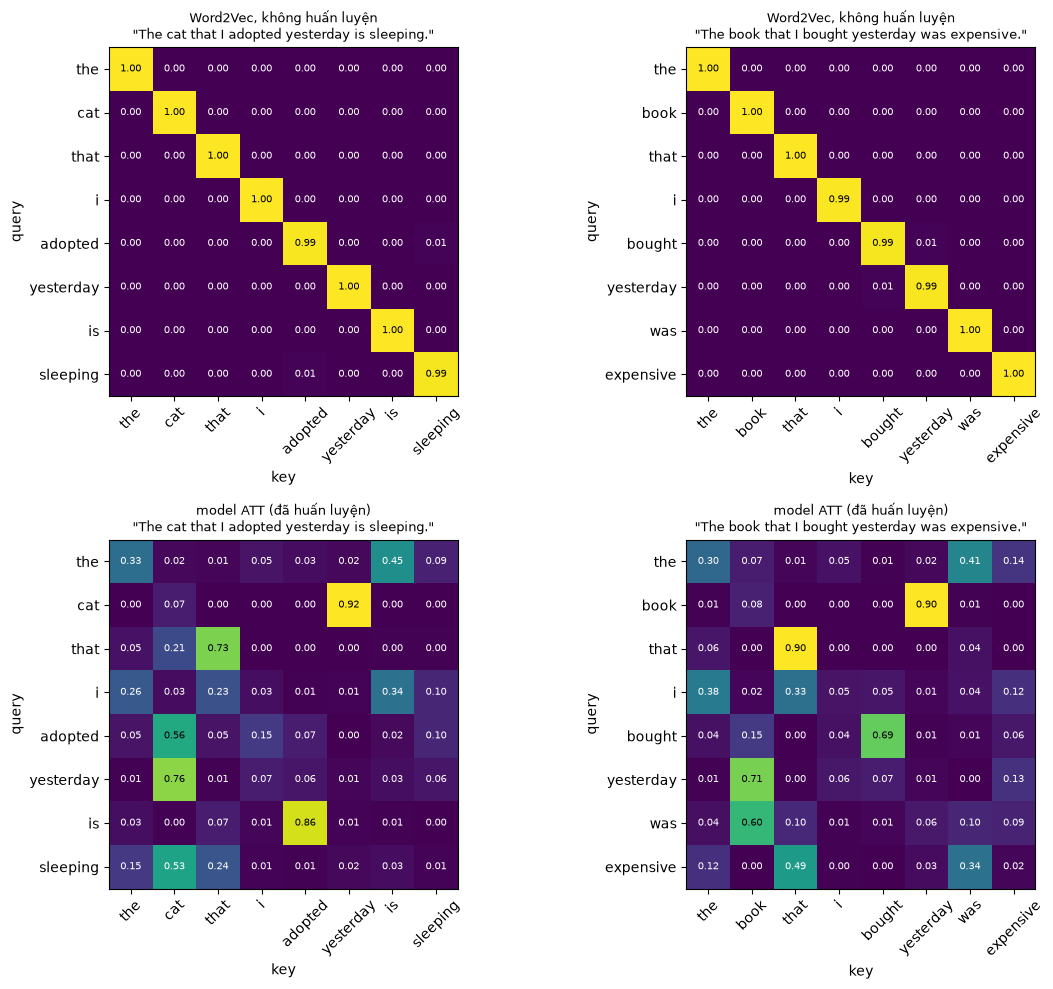

[Word2Vec] cat       → cat (1.00), sleeping (0.00), adopted (0.00)
[Word2Vec] adopted   → adopted (0.99), sleeping (0.01), cat (0.00)
[Word2Vec] sleeping  → sleeping (0.99), adopted (0.01), cat (0.00)
[ATT     ] cat       → yesterday (0.92), cat (0.07), i (0.00)
[ATT     ] adopted   → cat (0.56), i (0.15), sleeping (0.10)
[ATT     ] sleeping  → cat (0.53), that (0.24), the (0.15)
[Word2Vec] book      → book (1.00), i (0.00), that (0.00)
[Word2Vec] bought    → bought (0.99), yesterday (0.01), was (0.00)
[Word2Vec] expensive → expensive (1.00), bought (0.00), was (0.00)
[ATT     ] book      → yesterday (0.90), book (0.08), the (0.01)
[ATT     ] bought    → bought (0.69), book (0.15), expensive (0.06)
[ATT     ] expensive → that (0.49), was (0.34), the (0.12)


In [13]:
@torch.no_grad()
def att_maps(model, text):
    toks = pp.tokenize(text)[:MAXLEN]; X, l = encode([text])
    logit, A, alpha = model(X, l, return_attn=True); n = len(toks)
    return toks, A[0, :n, :n].numpy(), alpha[0, :n].numpy(), float(torch.sigmoid(logit)[0])
sents3 = ["The cat that I adopted yesterday is sleeping.", "The book that I bought yesterday was expensive."]
fig, axes = plt.subplots(2, 2, figsize=(12, 10)); probe = {}
for j, s in enumerate(sents3):
    tk = pp.tokenize(s); Xs = vecs(tk); _, Aw, _ = scaled_dot_product_attention(Xs, Xs, Xs)
    tk2, At, _, _ = att_maps(att, s)
    for i, (Am, title) in enumerate(((Aw, "Word2Vec, không huấn luyện"), (At, "model ATT (đã huấn luyện)"))):
        ax = axes[i, j]; ax.imshow(Am, cmap="viridis", vmin=0, vmax=Am.max())
        ax.set_xticks(range(len(tk))); ax.set_xticklabels(tk, rotation=45); ax.set_yticks(range(len(tk))); ax.set_yticklabels(tk)
        for a_ in range(len(tk)):
            for b_ in range(len(tk)): ax.text(b_, a_, f"{Am[a_, b_]:.2f}", ha="center", va="center", fontsize=7, color="white" if Am[a_, b_] < Am.max()*.6 else "black")
        ax.set_title(f"{title}\n\"{s}\"", fontsize=9); ax.set_xlabel("key"); ax.set_ylabel("query"); probe[(j, i)] = (tk, Am)
plt.tight_layout(); plt.savefig("attention_heatmap.png", dpi=130); plt.show()
for (j, i), (tk, Am) in probe.items():
    src = "Word2Vec" if i == 0 else "ATT"
    for w in ({0: ("cat", "adopted", "sleeping"), 1: ("book", "bought", "expensive")}[j]):
        r = Am[tk.index(w)]; top = np.argsort(-r)[:3]
        print(f"[{src:8s}] {w:9s} → " + ", ".join(f"{tk[t]} ({r[t]:.2f})" for t in top))
        log("exp3_visualization", f"{src}|{w}", "top3", ";".join(f"{tk[t]}:{r[t]:.2f}" for t in top))

**Nhận xét Experiment 3 — attention pattern, không phải linguistic explanation:**
- Word2Vec không huấn luyện (Q = K = V = X): mỗi token attend gần như toàn bộ vào **chính nó** (≈ 0.99), vì q·q lớn hơn hẳn q·k khi chưa có W_Q, W_K. Không có tương tác đáng kể giữa các token.
- Model ATT: **adopted → cat (0.56)** và **sleeping → cat (0.53)**, tức hai động từ đều nhìn về chủ ngữ "cat", trùng với quan hệ ngữ pháp mà con người thấy. Nhưng **cat → yesterday (0.92)** và **book → yesterday (0.90)**, **expensive → that / was**, những pattern không có giải thích ngôn ngữ rõ ràng.
- Vì model chỉ được huấn luyện để phân loại sentiment, đây là **phân phối attention** quan sát được. Một vài pattern trùng trực giác (adopted/sleeping → cat) không chứng minh model "hiểu ngữ pháp"; các pattern còn lại (→ yesterday) cho thấy không thể đọc heatmap như lời giải thích.

## 25 / 29. Experiment 5 — Sequence length và computational cost
Số phần tử của attention matrix T × T, bộ nhớ (float32) và thời gian đo thật của `scaled_dot_product_attention` (NumPy, d_k = 64, 1 head, 1 câu).

,attention_matrix,elements,memory_MB,time_ms
T,,,,
10,10×10,100,0.00,0.03
100,100×100,10000,0.04,0.34
500,500×500,250000,1.00,8.24
1000,1000×1000,1000000,4.00,41.11
2000,2000×2000,4000000,16.00,138.85
4000,4000×4000,16000000,64.00,768.10


T = 10,000 → 100,000,000 phần tử ≈ 400.0 MB cho một attention matrix float32


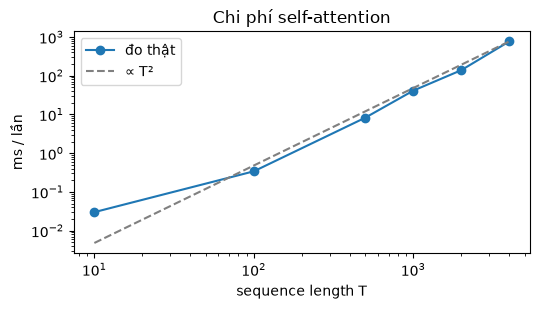

In [14]:
rows = []; rng = np.random.default_rng(SEED)
for T in (10, 100, 500, 1000, 2000, 4000):
    Qr = rng.normal(size=(T, 64)).astype(np.float32)
    t0 = time.perf_counter(); reps = max(1, int(200 // max(1, T // 50)))
    for _ in range(reps): scaled_dot_product_attention(Qr, Qr, Qr)
    dt = (time.perf_counter() - t0) / reps * 1000
    rows.append(dict(T=T, attention_matrix=f"{T}×{T}", elements=T*T, memory_MB=round(T*T*4/1e6, 2), time_ms=round(dt, 2)))
    log("exp5_cost", f"T={T}", "elements|time_ms", f"{T*T}|{dt:.3f}")
t5 = pd.DataFrame(rows).set_index("T"); display(t5)
print("T = 10,000 →", f"{10000**2:,}", "phần tử ≈", 10000**2*4/1e6, "MB cho một attention matrix float32")
fig, ax = plt.subplots(figsize=(5.5, 3.2)); ax.loglog(t5.index, t5.time_ms, "o-", label="đo thật")
ref = t5.time_ms.iloc[-1] * (t5.index / t5.index[-1])**2; ax.loglog(t5.index, ref, "--", color="gray", label="∝ T²")
ax.set_xlabel("sequence length T"); ax.set_ylabel("ms / lần"); ax.legend(); ax.set_title("Chi phí self-attention"); plt.tight_layout(); plt.show()

**Nhận xét Experiment 5:** T tăng 10 lần (100 → 1000) thì số phần tử tăng 100 lần (10⁴ → 10⁶) và thời gian đo cũng tăng cỡ 100 lần; từ 1000 → 4000 (×4) thời gian tăng gần 16–19 lần, bám theo đường T² (số đo thời gian dao động nhẹ giữa các lần chạy; ở T nhỏ chi phí cố định chiếm phần lớn). Với T = 10,000 một attention matrix float32 đã cần 400 MB cho một head, một câu, chưa kể batch, nhiều head, nhiều layer và gradient. Vì vậy full self-attention khó dùng cho sequence rất dài, còn RNN có chi phí gần tuyến tính theo T.

## 26. Application — Context-aware sentiment
Model **ATT**. Với mỗi câu: prediction, probability, attention pooling weight của từng token (token nào đóng góp vào context vector) và self-attention matrix. Để kiểm tra attention có phải giải thích hay không, so với **occlusion** (bỏ từng token, đo thay đổi P(positive)).

"I like this movie." → Negative (P(positive) = 0.091)
   pooling weight: i 0.26, like 0.25, this 0.26, movie 0.22
   occlusion Δp  : i -0.05, like -0.59, this -0.15, movie -0.06
"I do not like this movie." → Negative (P(positive) = 0.005)
   pooling weight: i 0.17, do 0.20, not 0.14, like 0.15, this 0.15, movie 0.19
   occlusion Δp  : i +0.00, do -0.02, not -0.04, like -0.03, this -0.04, movie -0.08
"I thought this movie would be bad, but it was actually excellent." → Positive (P(positive) = 0.803)
   pooling weight: i 0.07, thought 0.08, this 0.08, movie 0.08, would 0.10, be 0.07, bad 0.09, but 0.07, it 0.09, was 0.10, actually 0.11, excellent 0.07
   occlusion Δp  : i +0.63, thought +0.58, this +0.61, movie +0.53, would -0.02, be +0.51, bad -0.20, but +0.36, it +0.35, was -0.14, actually -0.10, excellent +0.79


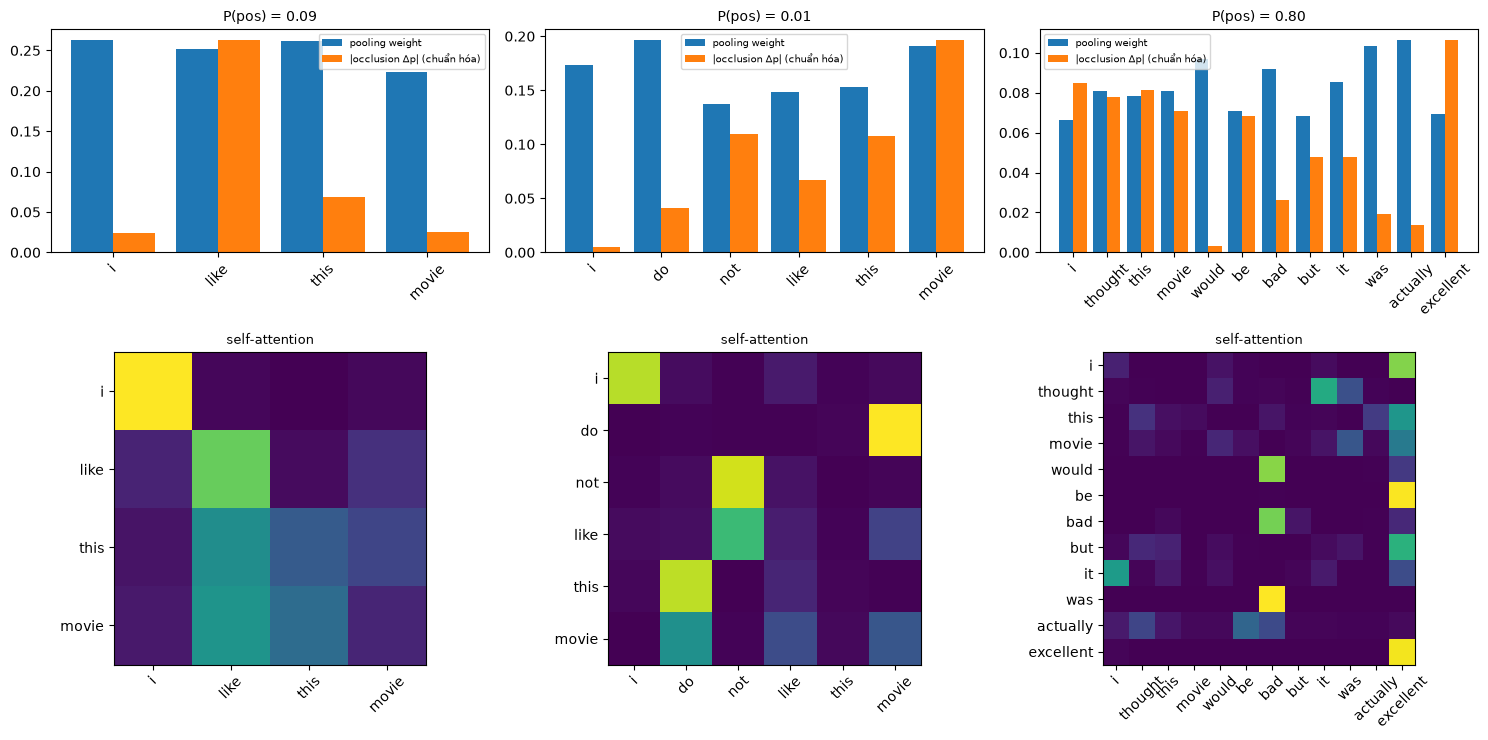

In [15]:
def prob(model, text): X, l = encode([text]); return float(predict(model, X, l)[0])
def occlusion(model, text):
    tk = pp.tokenize(text)[:MAXLEN]; p = prob(model, text)
    return np.array([p - prob(model, " ".join(tk[:i] + tk[i+1:])) for i in range(len(tk))])
app = ["I like this movie.", "I do not like this movie.", "I thought this movie would be bad, but it was actually excellent."]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), gridspec_kw=dict(height_ratios=[1, 1.4]))
for j, s in enumerate(app):
    tk, A_, al, p = att_maps(att, s); occ = occlusion(att, s)
    print(f"\"{s}\" → {'Positive' if p >= .5 else 'Negative'} (P(positive) = {p:.3f})")
    print("   pooling weight:", ", ".join(f"{t} {w:.2f}" for t, w in zip(tk, al)))
    print("   occlusion Δp  :", ", ".join(f"{t} {d:+.2f}" for t, d in zip(tk, occ)))
    log("application", s, "P_positive", round(p, 4))
    ax = axes[0, j]; x_ = np.arange(len(tk)); ax.bar(x_ - .2, al, .4, label="pooling weight"); ax.bar(x_ + .2, np.abs(occ) / max(np.abs(occ).max(), 1e-9) * al.max(), .4, label="|occlusion Δp| (chuẩn hóa)")
    ax.set_xticks(x_); ax.set_xticklabels(tk, rotation=45); ax.set_title(f"P(pos) = {p:.2f}", fontsize=10); ax.legend(fontsize=7)
    ax = axes[1, j]; ax.imshow(A_, cmap="viridis"); ax.set_xticks(x_); ax.set_xticklabels(tk, rotation=45); ax.set_yticks(x_); ax.set_yticklabels(tk); ax.set_title("self-attention", fontsize=9)
plt.tight_layout(); plt.show()

In [16]:
# So sánh cùng 3 câu trên mọi model của Experiment 4
display(pd.DataFrame({n: [round(prob(load(n), s), 3) for s in app] for n in runs}, index=app).rename_axis("P(positive)"))

,LSTM,ATT,ATT_nopos,POOL
P(positive),,,,
I like this movie.,0.578,0.091,0.020,0.008
I do not like this movie.,0.256,0.005,0.001,0.000
"I thought this movie would be bad, but it was actually excellent.",0.877,0.803,0.046,0.584


**Phân tích Application (model ATT):**
- **Đúng:** "I do not like this movie." → Negative (0.005) và câu tương phản "... would be bad, but it was actually excellent." → Positive (0.803). Ở câu tương phản, occlusion cho thấy bỏ **excellent** làm P(positive) giảm 0.79, còn bỏ **bad** làm tăng 0.20: model dùng cả hai từ đánh giá và để "excellent" thắng.
- **Sai:** "I like this movie." → Negative (0.091). Bỏ "like" làm P(positive) giảm 0.59, nên "like" có đẩy về positive, nhưng chưa đủ. Giả thuyết ban đầu "do positional embedding" **bị bác bỏ** bởi bảng trên: ATT_nopos (0.020) và POOL (0.008) cũng dự đoán Negative, chỉ LSTM đúng (0.578). Giả thuyết còn lại: domain shift: model chỉ thấy review dài (trung vị ≈ 170 token), câu 4 token không có từ khen mạnh; "like" trong IMDb hay xuất hiện ở ngữ cảnh trung tính/tiêu cực ("looks like", "felt like", "I'd like my money back") nên tự nó không đủ mạnh.
- Bảng cũng cho thấy với câu tương phản, ATT (có vị trí) đúng (0.803) còn ATT_nopos (0.046) và POOL (0.584, sát ngưỡng) yếu hơn: thông tin vị trí có ích cho cấu trúc "bad, but ... excellent", dù trên toàn test set ATT_nopos có F1 cao hơn.
- **Attention pooling gần như đều** (câu 4 token: 0.22–0.26; câu 12 token: 0.07–0.11) trong khi occlusion chênh lệch rất mạnh. Weight pooling **không** chỉ ra token quyết định; thông tin "từ nào quan trọng" đã được trộn vào vector của mọi vị trí bởi self-attention ở layer trước.

## 27. Error analysis (model ATT)
Chọn ngẫu nhiên (seed 2026) 3 mẫu đúng và 3 mẫu sai trên test. Với mỗi mẫu: top-5 token theo attention pooling weight và top-5 theo occlusion. Sau đó kiểm chứng định lượng trên 300 mẫu test: attention và occlusion có chọn cùng token quan trọng không.

In [17]:
pa = runs["ATT"]["test_probs"]; pred = (pa >= .5).astype(int); T_ = test.text.values
tl_ = np.array([len(pp.tokenize(t)) for t in T_]); lab = {0: "negative", 1: "positive"}
rng = np.random.RandomState(SEED)
ok = rng.choice(np.where((pred == y) & (tl_ <= 120))[0], 3, replace=False)
bad = rng.choice(np.where((pred != y) & (tl_ <= 120))[0], 3, replace=False)          # chọn review ≤ 120 token để đọc được toàn bộ
def top(tk, v, k=5): i = np.argsort(-v)[:k]; return ", ".join(f"{tk[t]}({v[t]:+.2f})" if v.min() < 0 else f"{tk[t]}({v[t]:.2f})" for t in i)
for title, idx in (("ĐÚNG", ok), ("SAI", bad)):
    print(f"===== {title} =====")
    for i in idx:
        tk, _, al, p = att_maps(att, T_[i]); occ = occlusion(att, T_[i])
        print(f"[{lab[y[i]]} → {lab[pred[i]]}] p={p:.2f} len={tl_[i]}\n  {T_[i]}\n  attention top-5: {top(tk, al)}\n  occlusion top-5 (|Δp|): {top(tk, np.abs(occ))}\n")
        log("error_analysis", f"{title}|test_idx={i}", "p|len", f"{p:.3f}|{tl_[i]}")

===== ĐÚNG =====


[negative → negative] p=0.33 len=109
  movie goers - avoid watching this movie. if you are faint hearted, you might want to commit suicide. if you are a short tempered, you would want to kill the lead performer of the movie. Though he does not have any talent in acting, he is the mass hero for all the rickshaw pullers,auto rickshaw drivers, rowdies, thugs and immature and ignorant literates. he proves - you do not need neither talent nor knowledge to be successfully. He is the highest paid actor in India. That shows the taste of movie going public in India. 90% of movie goers in tamil nadu are definitely attracted to his kind of nonsense movies.
  attention top-5: of(0.01), do(0.01), acting(0.01), rickshaw(0.01), paid(0.01)
  occlusion top-5 (|Δp|): definitely(0.16), goers(0.14), movie(0.14), though(0.14), you(0.13)

[negative → negative] p=0.18 len=112
  MGM hodgepodge of Jimmy Durante throwing a big party for everybody in Hollywood. No major stars show up--we get the Three Stooges, L

[positive → positive] p=0.91 len=117
  No matter how many times Wile Ethelbert "Famishius Famishius" Coyote tries to get Road "Burnius Roadibus" Runner, we always know what's going to happen, though our sympathy always remains with WEC. The highlight in "Hook, Line and Stinker" is a Rube Goldberg-style scheme that WEC hopes will finally finish off RR; but of course you know what happens. So, Wile E. continues hilarious engaging in fanaticism (defined by George Santayana as redoubling your effort after you've forgotten your aim) while Road Runner pretty much never becomes aware of the potential danger - or lack thereof - in which he could find himself. A real classic. And yes, the coyote's middle name is Ethelbert. I learned that from "Jeopardy!".
  attention top-5: happens(0.01), finish(0.01), off(0.01), redoubling(0.01), much(0.01)
  occlusion top-5 (|Δp|): hilarious(0.06), you've(0.04), you(0.04), as(0.04), to(0.04)

===== SAI =====
[positive → negative] p=0.04 len=102
  From the wri

[negative → positive] p=0.59 len=119
  Was it foreshadowing when Tori complained that her first boyfriend was treating her like a robot, and then her new boyfriend (the murderer) turned out to be a designer of artificial intelligence? I think so. Scenes to make you squeal with delight: montages galore, a strip-tease in a kimono (what do you call it when you seductively put clothes on, instead of take them off?), and a climactic battle on skis! Definitely tune in for the beginning and end, but you can grab a sandwich during the second act when all the plot is happening. Is it better than CO-ED CALL GIRL? Nah. Does Tori ever make it to paradise, or out of the snow, even? Nope.
  attention top-5: put(0.01), instead(0.01), kimono(0.01), climactic(0.01), do(0.01)
  occlusion top-5 (|Δp|): instead(0.24), them(0.14), climactic(0.14), off(0.13), of(0.13)

[negative → positive] p=0.79 len=91
  A so common horror story about a luxury building at Brooklyn which hides the gates to hell. It is remi

In [18]:
# Kiểm chứng: attention weight cao có trùng với token ảnh hưởng nhất (occlusion) không?
rng = np.random.RandomState(SEED); sample = rng.choice(np.where(tl_ <= 120)[0], 300, replace=False)
hit, overlap, rnd = [], [], []
for i in sample:
    tk, _, al, _ = att_maps(att, T_[i]); occ = np.abs(occlusion(att, T_[i])); k = 5
    A5, O5 = set(np.argsort(-al)[:k]), set(np.argsort(-occ)[:k])
    hit.append(int(np.argmax(occ)) in A5); overlap.append(len(A5 & O5) / k)
    rnd.append(len(set(rng.choice(len(tk), k, replace=False)) & O5) / k)
print(f"token ảnh hưởng nhất (occlusion) nằm trong top-5 attention: {np.mean(hit):.1%}")
print(f"trùng top-5 attention vs top-5 occlusion: {np.mean(overlap):.1%} (chọn 5 token ngẫu nhiên: {np.mean(rnd):.1%})")
log("error_analysis", "ATT|300 test reviews<=120 tok", "top1_occl_in_top5_attn", round(float(np.mean(hit)), 3))
log("error_analysis", "ATT|300 test reviews<=120 tok", "top5_overlap_attn_vs_occl", round(float(np.mean(overlap)), 3))
log("error_analysis", "ATT|300 test reviews<=120 tok", "top5_overlap_random_vs_occl", round(float(np.mean(rnd)), 3))
err = pred != y
neg = np.array([bool(set(pp.tokenize(t)) & {"not", "no", "never", "n't", "don't", "didn't", "isn't", "wasn't"}) for t in T_])
print("tỉ lệ lỗi theo độ dài: ≤200 token %.3f | >200 token %.3f" % (err[tl_ <= 200].mean(), err[tl_ > 200].mean()))
print("tỉ lệ lỗi có từ phủ định: %.3f | không có: %.3f" % (err[neg].mean(), err[~neg].mean()))
log("error_analysis", "ATT", "err_len<=200|>200", f"{err[tl_<=200].mean():.3f}|{err[tl_>200].mean():.3f}")

token ảnh hưởng nhất (occlusion) nằm trong top-5 attention: 17.7%
trùng top-5 attention vs top-5 occlusion: 10.4% (chọn 5 token ngẫu nhiên: 6.7%)


tỉ lệ lỗi theo độ dài: ≤200 token 0.130 | >200 token 0.176
tỉ lệ lỗi có từ phủ định: 0.153 | không có: 0.129


**Bảng phân loại lỗi và đối chiếu attention** (3 mẫu sai ở trên; nguyên nhân là **hypothesis**, kiểm bằng occlusion):

| # | True → Pred (p) | Loại lỗi | Token sinh viên cho là quan trọng | Attention top-5 | Occlusion (token ảnh hưởng nhất) | Đối chiếu |
|---|---|---|---|---|---|---|
| 1 | positive → negative (0.04) | ambiguous wording (review khen chê lẫn lộn: "eerie and campy fun" nhưng "bad musical", "awful") | fun, campy, awful, bad | evangelist, macliamm, there's, halfway, recital | nothing, awful, bad | Model dựa vào từ chê thật sự có trong câu; nhãn positive khó đoán từ chữ. Attention không chỉ vào các từ này. |
| 2 | negative → positive (0.59) | sarcasm ("squeal with delight", "Definitely tune in for the beginning and end") | delight, Nah, Nope | put, instead, kimono, climactic, do | instead, them, climactic | Model không nhận ra mỉa mai; các từ chê "Nah", "Nope" không nằm trong top của cả hai cách. |
| 3 | negative → positive (0.79) | ambiguous wording + rare/lost token ("great names ... acting for food", "barely entertaining", "4/10" bị tokenizer bỏ chữ số) | barely, 4/10, not at all | guess, names, whereas, luxury, barely | great (0.23), surprising | "great" được hiểu như lời khen dù đang nói về dàn diễn viên; điểm 4/10 mất khi tokenize. |

**Attention có tập trung vào token mình dự đoán là quan trọng không?** Không. Attention pooling gần như đều (≈ 1/T, top-5 chỉ ≈ 0.01–0.02 mỗi token) nên top-5 attention gần như ngẫu nhiên. Trên 300 review test (≤ 120 token): token ảnh hưởng nhất theo occlusion chỉ nằm trong top-5 attention 17.7% số lần; top-5 attention và top-5 occlusion trùng 10.4%, chỉ hơn chọn ngẫu nhiên (6.7%) một chút.

**Có giải thích được prediction sai không?** Chỉ là **hypothesis**: không thể kết luận "attention nhìn sai từ nên model sai", vì ngay ở các mẫu **đúng** attention cũng không chỉ vào từ quyết định. Occlusion (thay đổi đầu ra khi bỏ token) phù hợp với prediction hơn: mẫu 1 sai vì các từ chê "awful", "bad"; mẫu 3 sai vì "great". Ngoài ra tỉ lệ lỗi tăng với review dài (13.0% → 17.6% khi > 200 token, do truncation) và với review có từ phủ định (15.3% so với 12.9%).

## Lưu kết quả

In [19]:
with open("results.csv", "w", newline="", encoding="utf8") as f:
    wr = csv.writer(f); wr.writerow(["experiment", "config", "metric", "value"]); wr.writerows(RESULTS)
print(len(RESULTS), "rows → results.csv")

97 rows → results.csv
